Hola **Rodrigo**!

Soy **Patricio Requena** 👋. Es un placer ser el revisor de tu proyecto el día de hoy!

Revisaré tu proyecto detenidamente con el objetivo de ayudarte a mejorar y perfeccionar tus habilidades. Durante mi revisión, identificaré áreas donde puedas hacer mejoras en tu código, señalando específicamente qué y cómo podrías ajustar para optimizar el rendimiento y la claridad de tu proyecto. Además, es importante para mí destacar los aspectos que has manejado excepcionalmente bien. Reconocer tus fortalezas te ayudará a entender qué técnicas y métodos están funcionando a tu favor y cómo puedes aplicarlos en futuras tareas. 

_**Recuerda que al final de este notebook encontrarás un comentario general de mi parte**_, empecemos!

Encontrarás mis comentarios dentro de cajas verdes, amarillas o rojas, ⚠️ **por favor, no muevas, modifiques o borres mis comentarios** ⚠️:


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si todo está perfecto.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si de pronto hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma:
<div class="alert alert-block alert-info">
<b>Respuesta del estudiante</b> <a class=“tocSkip”></a>
</div>

# Sprint 17 · Film Junky Union
## Clasificación de sentimiento en reseñas de IMDB
**Autor:** Rodrigo Andrés Ardila Reyes  
**Objetivo:** clasificar reseñas como negativas (`0`) o positivas (`1`) y alcanzar **F1 ≥ 0.85** en prueba.

Se comparan tres algoritmos distintos: **regresión logística, SVM lineal y Complement Naive Bayes**, más una referencia constante. Se utilizan todos los datos de la partición oficial de prueba. **No se utiliza BERT**: TF-IDF permite resolver el problema en CPU sin descargar modelos de lenguaje.

El notebook incluye exploración, limpieza, vectorización, selección con validación interna, evaluación final, reseñas propias y conclusiones. Las reseñas propias están en inglés porque ese es el idioma del corpus.

**Ejecución:** colocar `imdb_reviews.tsv` o `imdb_reviews(2).tsv` junto al notebook y ejecutar las celdas en orden. También se reconoce `/datasets/imdb_reviews.tsv`, la ruta de TripleTen. Dependencias: Python 3, pandas, NumPy, matplotlib y scikit-learn. No requiere internet, GPU, NLTK ni spaCy.

**Fuente del conjunto de datos:** Maas, A. L., Daly, R. E., Pham, P. T., Huang, D., Ng, A. Y. y Potts, C. (2011). *Learning Word Vectors for Sentiment Analysis*. ACL 2011. Datos facilitados por el proyecto.

## 1. Inicialización

In [1]:
from pathlib import Path
import html
import re
import time
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)

RANDOM_STATE = 42
F1_TARGET = 0.85
np.random.seed(RANDOM_STATE)
plt.style.use('ggplot')
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.max_columns', 20)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | '
      f'NumPy {np.__version__} | scikit-learn {sklearn.__version__}')

Python 3.12.14 | pandas 2.2.3 | NumPy 2.3.5 | scikit-learn 1.8.0


## 2. Carga y revisión de los datos

In [2]:
candidates = [
    Path('/datasets/imdb_reviews.tsv'),
    Path('imdb_reviews.tsv'), Path('imdb_reviews(2).tsv'),
    Path('upload/imdb_reviews.tsv'), Path('upload/imdb_reviews(2).tsv'),
]
DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Coloca imdb_reviews.tsv junto al notebook o en /datasets/.')

df_reviews = pd.read_csv(DATA_PATH, sep='\t', dtype={'votes': 'Int64'})
required = {'review', 'pos', 'ds_part'}
assert required.issubset(df_reviews.columns), 'Faltan columnas necesarias.'
print('Archivo:', DATA_PATH)
print('Dimensiones:', df_reviews.shape)
display(df_reviews.head(3))
df_reviews.info()

Archivo: upload/imdb_reviews(2).tsv
Dimensiones: (47331, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47331 entries, 0 to 47330
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           47331 non-null  object 
 1   title_type       47331 non-null  object 
 2   primary_title    47331 non-null  object 
 3   original_title   47331 non-null  object 
 4   start_year       47331 non-null  int64  
 5   end_year         47331 non-null  object 
 6   runtime_minutes  47331 non-null  object 
 7   is_adult         47331 non-null  int64  
 8   genres           47331 non-null  object 
 9   average_rating   47329 non-null  float64
 10  votes            47329 non-null  Int64  
 11  review           47331 non-null  object 
 12  rating           47331 non-null  int64  
 13  sp               47331 non-null  object 
 14  pos              47331 non-null  int64  
 15  ds_part          47331 non-null  object 
 1

,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
0,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,"The pakage implies that Warren Beatty and Goldie Hawn are pulling off a huge bank robbery, but that's not ...",1,neg,0,train,8335
1,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,"How the hell did they get this made?! Presenting itself as a caper comedy, the misbegotten ""$"" is essentia...",1,neg,0,train,8336
2,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,There is no real story the film seems more like a fly on the wall drama-documentary than a proper film so ...,3,neg,0,test,2489


In [3]:
quality = pd.DataFrame({
    'tipo': df_reviews.dtypes.astype(str),
    'nulos': df_reviews.isna().sum(),
    'valores_distintos': df_reviews.nunique(),
})
display(quality)
print('Duplicados de todas las columnas:', df_reviews.duplicated().sum())
print('Reseñas repetidas (texto original):', df_reviews['review'].duplicated().sum())
display(pd.crosstab(df_reviews['ds_part'], df_reviews['pos']))
assert df_reviews['review'].notna().all()
assert df_reviews['review'].map(lambda x: isinstance(x, str)).all()
assert df_reviews['pos'].isin([0, 1]).all()
assert set(df_reviews['ds_part']) == {'train', 'test'}
df_reviews['pos'] = df_reviews['pos'].astype('int8')

Duplicados de todas las columnas: 0
Reseñas repetidas (texto original): 91


,tipo,nulos,valores_distintos
tconst,object,0,6648
title_type,object,0,10
primary_title,object,0,6555
original_title,object,0,6562
start_year,int64,0,107
end_year,object,0,60
runtime_minutes,object,0,249
is_adult,int64,0,2
genres,object,0,585
average_rating,float64,2,83


pos,0,1
ds_part,,
test,11803,11732
train,11912,11884


Las columnas esenciales no tienen nulos. Los nulos en `average_rating` y `votes` se conservan: no se utilizarán para entrenar. El modelo recibirá **únicamente el texto**; se excluyen `rating`, `pos` y otros metadatos de las características. La puntuación de la reseña revelaría directamente el sentimiento y produciría fuga de información.

No basta con revisar filas idénticas: la misma reseña puede aparecer con distintos identificadores. Más adelante se revisan también los textos normalizados. Se respeta `ds_part`; no se mezclan las particiones oficiales.

## 3. Análisis exploratorio

,Negativa (0),Positiva (1)
ds_part,,
train,11912,11884
test,11803,11732


,Negativa (0),Positiva (1)
Porcentaje por partición,,
train,50.06,49.94
test,50.15,49.85


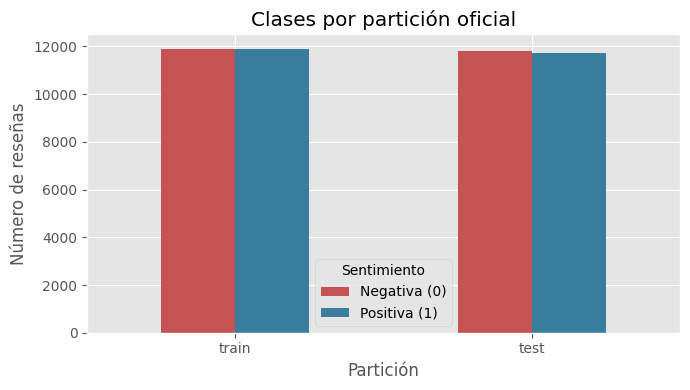

In [4]:
class_counts = pd.crosstab(df_reviews['ds_part'], df_reviews['pos']).reindex(['train', 'test'])
class_counts.columns = ['Negativa (0)', 'Positiva (1)']
class_percent = class_counts.div(class_counts.sum(axis=1), axis=0) * 100
display(class_counts)
display(class_percent.round(2).rename_axis('Porcentaje por partición'))

fig, ax = plt.subplots(figsize=(7, 4))
class_counts.plot.bar(ax=ax, color=['#c55353', '#397e9f'], rot=0)
ax.set(title='Clases por partición oficial', xlabel='Partición', ylabel='Número de reseñas')
ax.legend(title='Sentimiento')
plt.tight_layout()
plt.show()

In [5]:
negative_pct = 100 * (df_reviews['pos'] == 0).mean()
display(Markdown(
    f'**Equilibrio de clases:** {negative_pct:.2f}% negativas y '
    f'{100-negative_pct:.2f}% positivas. Las dos particiones están prácticamente '
    'equilibradas. No se justifica aplicar sobremuestreo, submuestreo o ponderación '
    'de clases. F1 será la métrica principal; se reportan también F1 de la clase '
    'negativa y F1 macro porque el objetivo de negocio es detectar críticas negativas.'
))

**Equilibrio de clases:** 50.10% negativas y 49.90% positivas. Las dos particiones están prácticamente equilibradas. No se justifica aplicar sobremuestreo, submuestreo o ponderación de clases. F1 será la métrica principal; se reportan también F1 de la clase negativa y F1 macro porque el objetivo de negocio es detectar críticas negativas.

Años representados: 1894 a 2010
Películas distintas: 6648


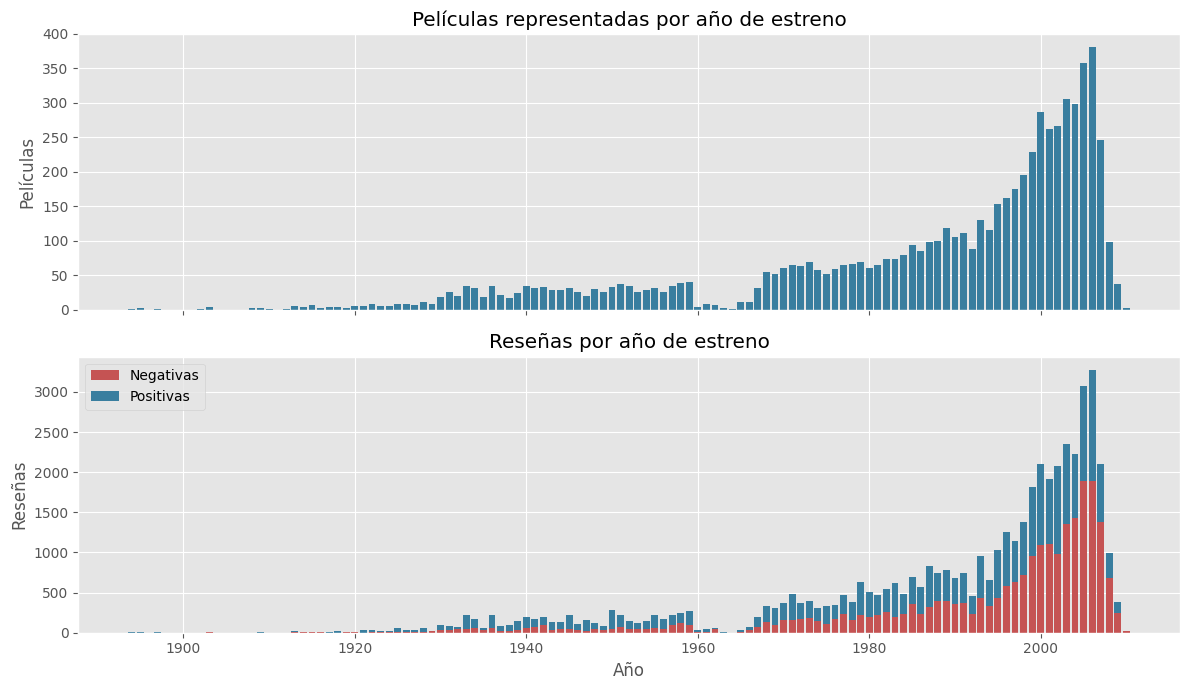

In [6]:
years = pd.to_numeric(df_reviews['start_year'], errors='coerce')
eda = df_reviews.assign(year=years)
movies_by_year = eda[['tconst', 'year']].drop_duplicates().groupby('year').size()
reviews_by_year = eda.groupby(['year', 'pos']).size().unstack(fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].bar(movies_by_year.index, movies_by_year.values, color='#397e9f')
axes[0].set(title='Películas representadas por año de estreno', ylabel='Películas')
axes[1].bar(reviews_by_year.index, reviews_by_year[0], label='Negativas', color='#c55353')
axes[1].bar(reviews_by_year.index, reviews_by_year[1], bottom=reviews_by_year[0],
            label='Positivas', color='#397e9f')
axes[1].set(title='Reseñas por año de estreno', xlabel='Año', ylabel='Reseñas')
axes[1].legend()
plt.tight_layout()
plt.show()
print('Años representados:', int(years.min()), 'a', int(years.max()))
print('Películas distintas:', df_reviews['tconst'].nunique())

count   mean    std   min    25%    50%    75%     max
ds_part pos                                                          
test    0    11803.0  226.0  162.1   4.0  126.0  172.0  275.0  1083.0
        1    11732.0  227.3  173.2  10.0  123.0  169.0  274.0  2235.0
train   0    11912.0  229.0  164.8  10.0  127.0  174.0  277.0  1491.0
        1    11884.0  235.4  179.5  12.0  125.0  173.0  290.0  2459.0

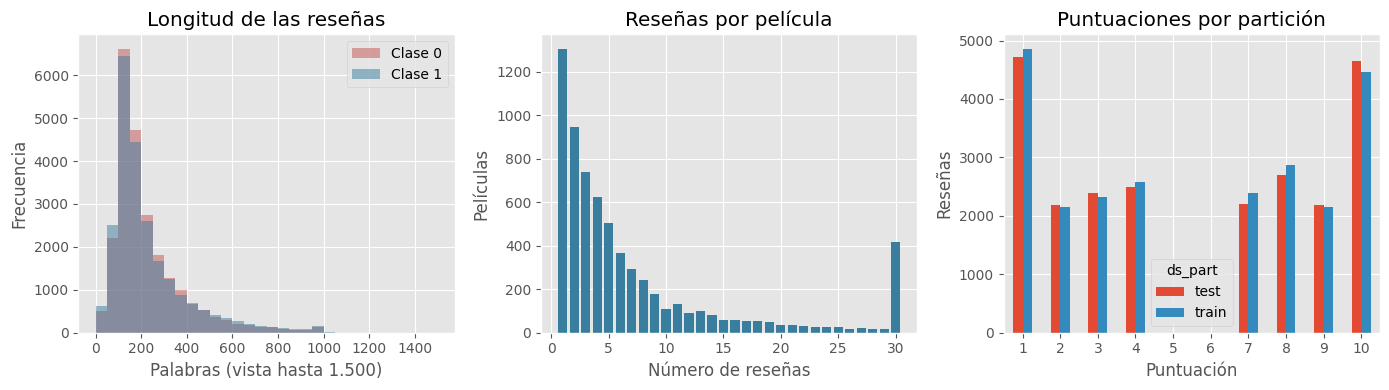

In [7]:
review_lengths = df_reviews['review'].str.split().str.len()
length_summary = df_reviews.assign(words=review_lengths).groupby(['ds_part', 'pos'])['words'].describe()
display(length_summary.round(1))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for label, color in [(0, '#c55353'), (1, '#397e9f')]:
    axes[0].hist(review_lengths[df_reviews['pos'] == label], bins=np.arange(0, 1501, 50),
                 alpha=0.5, label=f'Clase {label}', color=color)
axes[0].set(title='Longitud de las reseñas', xlabel='Palabras (vista hasta 1.500)', ylabel='Frecuencia')
axes[0].legend()
per_movie = df_reviews.groupby('tconst').size().value_counts().sort_index()
axes[1].bar(per_movie.index, per_movie.values, color='#397e9f')
axes[1].set(title='Reseñas por película', xlabel='Número de reseñas', ylabel='Películas')
ratings = pd.crosstab(df_reviews['rating'], df_reviews['ds_part']).reindex(range(1, 11), fill_value=0)
ratings.plot.bar(ax=axes[2], rot=0)
axes[2].set(title='Puntuaciones por partición', xlabel='Puntuación', ylabel='Reseñas')
plt.tight_layout()
plt.show()

**Conclusión del EDA.** Predominan las películas de las últimas décadas representadas en el corpus, por lo que no se garantiza el mismo rendimiento en cualquier época o comunidad. Las reseñas tienen longitudes muy variadas y una película puede aportar varios textos. Las puntuaciones se concentran en opiniones claramente negativas o positivas; las puntuaciones neutrales 5–6 están ausentes. El problema evalúa polaridad binaria y no modela una categoría neutral. El equilibrio global no implica equilibrio dentro de cada película o año.

<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Correcto. Siempre para la parte del EDA procura dejar redactado tus interpretaciones de lo que se puede observar ya que es importante primero entender los datos antes de pasar al entrenamiento de algún modelo.
</div>

## 4. Procedimiento de evaluación

Se reserva una validación interna a partir de `train` y se seleccionan hiperparámetros y algoritmo con **F1 positivo**, siguiendo la convención de scikit-learn (`pos_label=1`). Se reporta además F1 negativo (`pos_label=0`). La partición `test` se usa al final, una vez fijadas las decisiones.

Se mantienen los umbrales estándar: probabilidad 0.5 para los modelos probabilísticos y margen 0 para SVM. No se busca un umbral óptimo en prueba. ROC-AUC y average precision se calculan con probabilidades o márgenes continuos, nunca con etiquetas binarias. El margen de SVM **no es una probabilidad**.

In [8]:
def positive_score(model, features):
    """Puntuación continua de la clase positiva; SVM devuelve un margen."""
    if hasattr(model, 'predict_proba'):
        positive_index = list(model.classes_).index(1)
        return model.predict_proba(features)[:, positive_index]
    return model.decision_function(features)

def metrics_for(model, features, target):
    predictions = model.predict(features)
    score = positive_score(model, features)
    return {
        'accuracy': accuracy_score(target, predictions),
        'precision_pos': precision_score(target, predictions, zero_division=0),
        'recall_pos': recall_score(target, predictions, zero_division=0),
        'F1_pos': f1_score(target, predictions, pos_label=1, zero_division=0),
        'F1_neg': f1_score(target, predictions, pos_label=0, zero_division=0),
        'F1_macro': f1_score(target, predictions, average='macro', zero_division=0),
        'ROC_AUC': roc_auc_score(target, score),
        'AP_pos': average_precision_score(target, score),
    }

def evaluate_model(name, model, train_features, train_target, test_features, test_target):
    """Evalúa con parámetros fijos y grafica confusión, ROC y precisión-recall."""
    rows = []
    for part, features, target in [('train', train_features, train_target),
                                    ('test', test_features, test_target)]:
        rows.append({'modelo': name, 'particion': part, **metrics_for(model, features, target)})
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    predictions = model.predict(test_features)
    score = positive_score(model, test_features)
    ConfusionMatrixDisplay.from_predictions(
        test_target, predictions, display_labels=['Negativa', 'Positiva'],
        ax=axes[0], colorbar=False, cmap='Blues')
    RocCurveDisplay.from_predictions(test_target, score, ax=axes[1], name=name)
    axes[1].plot([0, 1], [0, 1], '--', color='gray')
    PrecisionRecallDisplay.from_predictions(test_target, score, ax=axes[2], name=name)
    axes[2].axhline(np.mean(test_target), linestyle='--', color='gray', label='Prevalencia positiva')
    axes[2].legend(fontsize=8)
    axes[0].set_title('Matriz de confusión · prueba')
    axes[1].set_title('ROC · prueba')
    axes[2].set_title('Precisión-recall · prueba')
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame(rows).set_index(['modelo', 'particion']).round(4))
    return rows

## 5. Normalización del texto

In [9]:
def normalize_text(text):
    text = html.unescape(str(text)).lower()
    text = re.sub(r'<[^>]*>', ' ', text)  # Por ejemplo, <br />.
    text = re.sub(r"n['’]t\b", ' not', text)  # Conservar explícitamente la negación.
    text = re.sub(r'[^a-z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

df_reviews['review_norm'] = df_reviews['review'].map(normalize_text)
print('Textos vacíos después de normalizar:', df_reviews['review_norm'].eq('').sum())
display(df_reviews[['review', 'review_norm']].head(3))

Textos vacíos después de normalizar: 0


,review,review_norm
0,"The pakage implies that Warren Beatty and Goldie Hawn are pulling off a huge bank robbery, but that's not ...",the pakage implies that warren beatty and goldie hawn are pulling off a huge bank robbery but that s not w...
1,"How the hell did they get this made?! Presenting itself as a caper comedy, the misbegotten ""$"" is essentia...",how the hell did they get this made presenting itself as a caper comedy the misbegotten is essentially two...
2,There is no real story the film seems more like a fly on the wall drama-documentary than a proper film so ...,there is no real story the film seems more like a fly on the wall drama documentary than a proper film so ...


Se eliminan HTML, dígitos y puntuación y se unifican minúsculas y espacios. Esta transformación no aprende parámetros, por lo que puede aplicarse a ambas particiones. **Se conservan las stopwords**, en especial `not`, `no` y `never`: eliminarlas puede invertir el significado. Los unigramas y bigramas ayudan a representar expresiones como `not good`.

No se aplica lematización. Es una decisión práctica que reduce dependencias y tiempo de ejecución; el vocabulario TF-IDF se aprende directamente del corpus. Esta normalización también pierde señales como signos de exclamación y puntuaciones numéricas, una limitación del enfoque.

<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Perfecto! Realizaste un buen trabajo con la normalización y creando la función de evaluación. La normalización es un paso importante para evitar "ruido" en tus datos y estandarizar el hecho que las palabras estén en casos escritas con mayúsculas y en otros con minúsculas
</div>

## 6. Particiones y prevención de contaminación

In [10]:
train_raw = df_reviews.loc[df_reviews['ds_part'].eq('train')].copy()
df_reviews_test = df_reviews.loc[df_reviews['ds_part'].eq('test')].copy()

# Diagnóstico sin usar las etiquetas de prueba para tomar decisiones.
overlap_texts = set(train_raw['review_norm']) & set(df_reviews_test['review_norm'])
overlap_movies = set(train_raw['tconst']) & set(df_reviews_test['tconst'])
print('Textos normalizados compartidos entre train y test:', len(overlap_texts))
print('Películas compartidas entre train y test:', len(overlap_movies))
print('Repeticiones normalizadas dentro de train:', train_raw['review_norm'].duplicated().sum())
print('Repeticiones normalizadas dentro de test:', df_reviews_test['review_norm'].duplicated().sum())

# Si un texto tiene etiquetas contradictorias en train, excluirlo de train.
label_counts = train_raw.groupby('review_norm')['pos'].nunique()
conflicting_texts = set(label_counts[label_counts > 1].index)
df_reviews_train = train_raw.loc[
    train_raw['review_norm'].ne('') &
    ~train_raw['review_norm'].isin(overlap_texts | conflicting_texts)
].drop_duplicates('review_norm').copy()

print('Train oficial:', len(train_raw), '| Train limpio:', len(df_reviews_train))
print('Test oficial conservado:', len(df_reviews_test))
assert set(df_reviews_train['review_norm']).isdisjoint(df_reviews_test['review_norm'])
assert len(df_reviews_test) == (df_reviews['ds_part'] == 'test').sum()

# Validación por película: sus reseñas quedan juntas en una sola partición.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
fit_idx, valid_idx = next(splitter.split(df_reviews_train, groups=df_reviews_train['tconst']))
fit_data = df_reviews_train.iloc[fit_idx]
valid_data = df_reviews_train.iloc[valid_idx]
assert set(fit_data['tconst']).isdisjoint(valid_data['tconst'])
assert set(fit_data['review_norm']).isdisjoint(valid_data['review_norm'])

display(pd.DataFrame({
    'filas': [len(fit_data), len(valid_data), len(df_reviews_train), len(df_reviews_test)],
    'proporcion_positiva': [d['pos'].mean() for d in
                          [fit_data, valid_data, df_reviews_train, df_reviews_test]],
}, index=['ajuste interno', 'validación interna', 'train limpio completo', 'test oficial']))

Textos normalizados compartidos entre train y test: 1
Películas compartidas entre train y test: 1
Repeticiones normalizadas dentro de train: 40
Repeticiones normalizadas dentro de test: 54
Train oficial: 23796 | Train limpio: 23755
Test oficial conservado: 23535


,filas,proporcion_positiva
ajuste interno,18860,0.494008
validación interna,4895,0.519714
train limpio completo,23755,0.499305
test oficial,23535,0.498492


Se retiran de entrenamiento las repeticiones normalizadas y los textos que también están en prueba; **no se cambia la prueba oficial**. La auditoría de coincidencias usa los textos del test para retirar contaminación, sin utilizar sus etiquetas para seleccionar modelos. Dentro de `train`, la validación se agrupa por película para no evaluar otras reseñas de una película ya vista en el ajuste interno. Esta división no es estratificada: la tabla permite comprobar sus proporciones de clase.

La limpieza deja textos únicos en entrenamiento. Las repeticiones de prueba se conservan para respetar la evaluación solicitada; esto limita la independencia estadística de sus observaciones. Una película compartida entre las particiones oficiales se documenta, pero no se rediseña la partición proporcionada.

## 7. Vectorización, entrenamiento y selección

### 7.1. TF-IDF sin fuga de información

In [11]:
def make_vectorizer():
    return TfidfVectorizer(
        lowercase=False,  # Los textos ya están normalizados.
        ngram_range=(1, 2), min_df=2, max_df=0.98,
        max_features=100_000, sublinear_tf=True,
        dtype=np.float32,
    )

validation_vectorizer = make_vectorizer()
start = time.perf_counter()
X_fit = validation_vectorizer.fit_transform(fit_data['review_norm'])
X_valid = validation_vectorizer.transform(valid_data['review_norm'])
y_fit = fit_data['pos'].to_numpy()
y_valid = valid_data['pos'].to_numpy()
print('Matriz de ajuste:', X_fit.shape, '| Validación:', X_valid.shape)
print('Tiempo de vectorización (s):', round(time.perf_counter() - start, 2))
print('Densidad de ajuste:', round(X_fit.nnz / np.prod(X_fit.shape), 6))

Matriz de ajuste: (18860, 100000) | Validación: (4895, 100000)
Tiempo de vectorización (s): 10.04
Densidad de ajuste: 0.00264


TF-IDF combina frecuencia dentro de una reseña con rareza entre documentos. Se limita el vocabulario a 100.000 características, se descartan términos que aparecen en un único documento y se usan matrices dispersas, sin convertirlas en arreglos densos. Durante la selección, el vocabulario y el IDF se ajustan **solo con el subconjunto de ajuste interno**. La validación se transforma con ese mismo vectorizador.

### 7.2. Tres algoritmos y una referencia constante

In [12]:
def make_estimator(family, parameter):
    if family == 'Regresión logística':
        return LogisticRegression(C=parameter, solver='liblinear', max_iter=1000,
                                  random_state=RANDOM_STATE)
    if family == 'SVM lineal':
        return LinearSVC(C=parameter, max_iter=5000, random_state=RANDOM_STATE)
    if family == 'Complement NB':
        return ComplementNB(alpha=parameter)
    if family == 'Constante':
        return DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
    raise ValueError(f'Familia desconocida: {family}')

search_space = {
    'Regresión logística': [1.0, 4.0],
    'SVM lineal': [0.5, 1.0],
    'Complement NB': [0.5, 1.0],
    'Constante': [None],
}
validation_rows = []
for family, parameters in search_space.items():
    for parameter in parameters:
        model = make_estimator(family, parameter)
        start = time.perf_counter()
        model.fit(X_fit, y_fit)
        elapsed = time.perf_counter() - start
        validation_rows.append({
            'modelo': family, 'parametro': parameter, 'tiempo_ajuste_s': elapsed,
            **metrics_for(model, X_valid, y_valid),
        })
        print(f'{family} | parámetro={parameter} | '
              f'F1 validación={validation_rows[-1]["F1_pos"]:.4f}')

validation_results = pd.DataFrame(validation_rows)
display(validation_results.sort_values('F1_pos', ascending=False).round(4))
selected_rows = validation_results.loc[
    validation_results.groupby('modelo', sort=False)['F1_pos'].idxmax()
].set_index('modelo')
best_name = selected_rows.drop(index='Constante')['F1_pos'].idxmax()
print('Modelo elegido antes de consultar resultados de prueba:', best_name)
display(selected_rows.round(4))

Regresión logística | parámetro=1.0 | F1 validación=0.8904
Regresión logística | parámetro=4.0 | F1 validación=0.8989
SVM lineal | parámetro=0.5 | F1 validación=0.8996
SVM lineal | parámetro=1.0 | F1 validación=0.8936
Complement NB | parámetro=0.5 | F1 validación=0.8683
Complement NB | parámetro=1.0 | F1 validación=0.8641
Constante | parámetro=None | F1 validación=0.0000
Modelo elegido antes de consultar resultados de prueba: SVM lineal


,modelo,parametro,tiempo_ajuste_s,accuracy,precision_pos,recall_pos,F1_pos,F1_neg,F1_macro,ROC_AUC,AP_pos
2,SVM lineal,0.5,0.3839,0.8964,0.9063,0.8931,0.8996,0.8930,0.8963,0.9610,0.9617
1,Regresión logística,4.0,0.8173,0.8954,0.9032,0.8947,0.8989,0.8917,0.8953,0.9607,0.9618
3,SVM lineal,1.0,0.5310,0.8905,0.9029,0.8844,0.8936,0.8873,0.8904,0.9596,0.9603
0,Regresión logística,1.0,0.5965,0.8858,0.8885,0.8923,0.8904,0.8808,0.8856,0.9564,0.9578
4,Complement NB,0.5,0.0154,0.8658,0.8859,0.8514,0.8683,0.8632,0.8657,0.9407,0.9377
5,Complement NB,1.0,0.0142,0.8629,0.8910,0.8388,0.8641,0.8617,0.8629,0.9407,0.9384
6,Constante,NaN,0.0004,0.4803,0.0000,0.0000,0.0000,0.6489,0.3245,0.5000,0.5197


,parametro,tiempo_ajuste_s,accuracy,precision_pos,recall_pos,F1_pos,F1_neg,F1_macro,ROC_AUC,AP_pos
modelo,,,,,,,,,,
Regresión logística,4.0,0.8173,0.8954,0.9032,0.8947,0.8989,0.8917,0.8953,0.9607,0.9618
SVM lineal,0.5,0.3839,0.8964,0.9063,0.8931,0.8996,0.8930,0.8963,0.9610,0.9617
Complement NB,0.5,0.0154,0.8658,0.8859,0.8514,0.8683,0.8632,0.8657,0.9407,0.9377
Constante,NaN,0.0004,0.4803,0.0000,0.0000,0.0000,0.6489,0.3245,0.5000,0.5197


La búsqueda es pequeña y está definida de antemano. `C` controla la regularización de los modelos lineales y `alpha` el suavizado de Naive Bayes. La regresión logística produce probabilidades; SVM busca una frontera con margen; Complement NB utiliza frecuencias con una hipótesis simplificadora de independencia. La referencia constante permite verificar que los modelos aprenden señales útiles del texto. No se cuenta como uno de los tres algoritmos exigidos.

La selección se basa en una única validación por grupos, no en validación cruzada exhaustiva. Los resultados de esa validación sirven para elegir; no constituyen la evaluación final.

### 7.3. Ajuste final con todo el entrenamiento limpio

In [13]:
tfidf_vectorizer = make_vectorizer()
X_train = tfidf_vectorizer.fit_transform(df_reviews_train['review_norm'])
X_test = tfidf_vectorizer.transform(df_reviews_test['review_norm'])
y_train = df_reviews_train['pos'].to_numpy()
y_test = df_reviews_test['pos'].to_numpy()
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Vocabulario final:', len(tfidf_vectorizer.vocabulary_))

models = {}
fit_times = {}
for family, row in selected_rows.iterrows():
    model = make_estimator(family, None if family == 'Constante' else float(row['parametro']))
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_times[family] = time.perf_counter() - start
    models[family] = model
    print(f'{family}: ajuste completado en {fit_times[family]:.2f} s')

Train: (23755, 100000) | Test: (23535, 100000)
Vocabulario final: 100000
Regresión logística: ajuste completado en 1.18 s
SVM lineal: ajuste completado en 0.48 s
Complement NB: ajuste completado en 0.02 s
Constante: ajuste completado en 0.00 s


### 7.4. Evaluación en la partición oficial de prueba

Modelo previamente seleccionado: SVM lineal
F1 positivo en prueba: 0.9028
F1 negativo en prueba: 0.9038


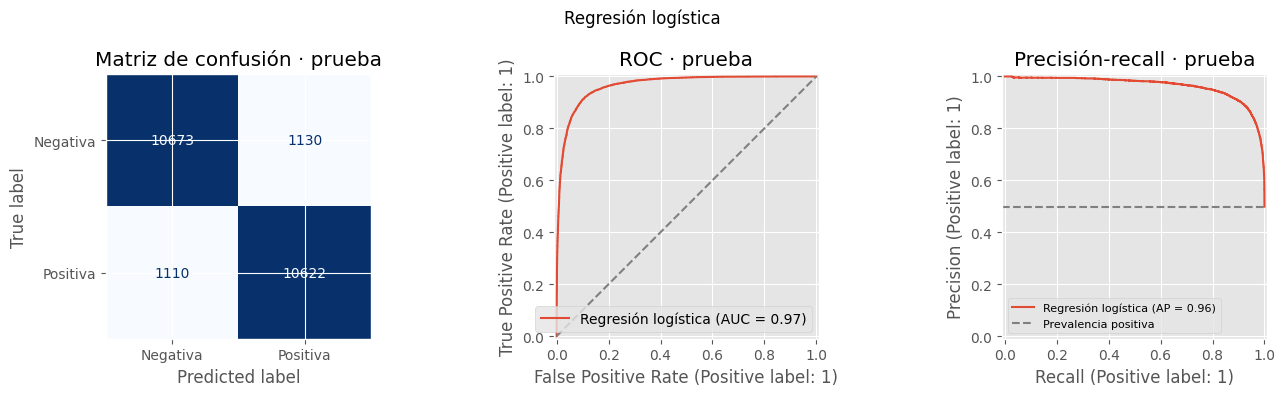

accuracy  precision_pos  recall_pos  F1_pos  \
modelo              particion                                                
Regresión logística train        0.9891         0.9892      0.9889  0.9890   
                    test         0.9048         0.9038      0.9054  0.9046   

                               F1_neg  F1_macro  ROC_AUC  AP_pos  
modelo              particion                                     
Regresión logística train      0.9891    0.9891   0.9991  0.9990  
                    test       0.9050    0.9048   0.9658  0.9637

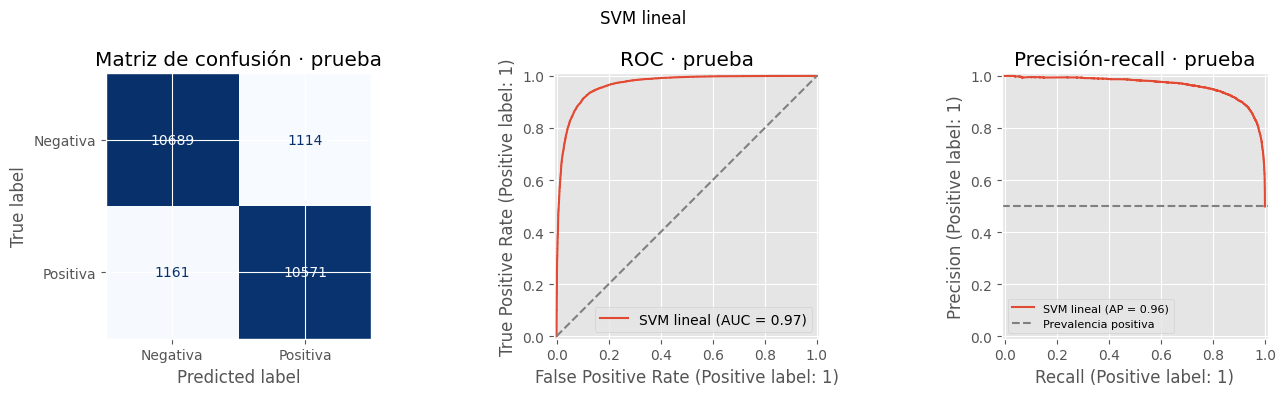

accuracy  precision_pos  recall_pos  F1_pos  F1_neg  \
modelo     particion                                                        
SVM lineal train        0.9956         0.9957      0.9955  0.9956  0.9956   
           test         0.9033         0.9047      0.9010  0.9028  0.9038   

                      F1_macro  ROC_AUC  AP_pos  
modelo     particion                             
SVM lineal train        0.9956   0.9998  0.9997  
           test         0.9033   0.9661  0.9640

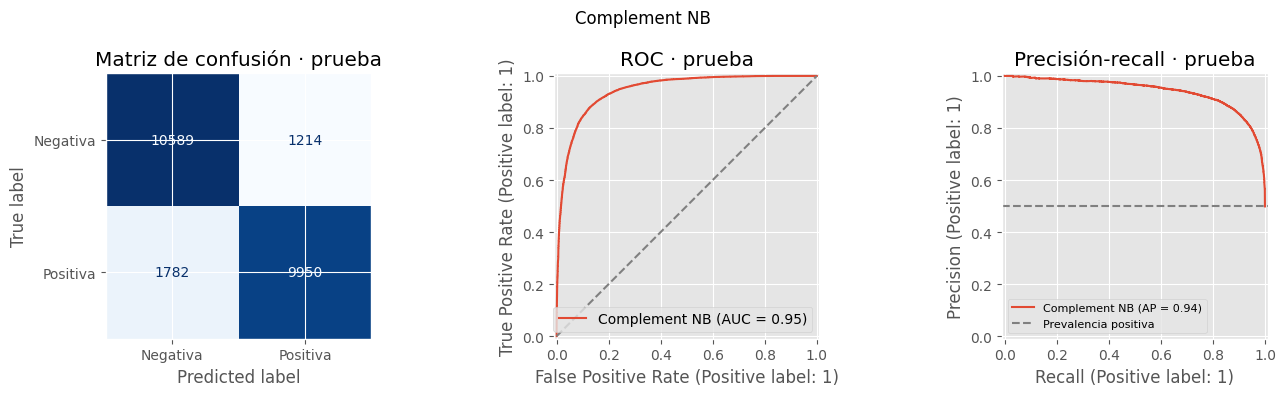

accuracy  precision_pos  recall_pos  F1_pos  F1_neg  \
modelo        particion                                                        
Complement NB train        0.9366         0.9405      0.9320  0.9363  0.9370   
              test         0.8727         0.8913      0.8481  0.8691  0.8761   

                         F1_macro  ROC_AUC  AP_pos  
modelo        particion                             
Complement NB train        0.9366   0.9841  0.9845  
              test         0.8726   0.9457  0.9420

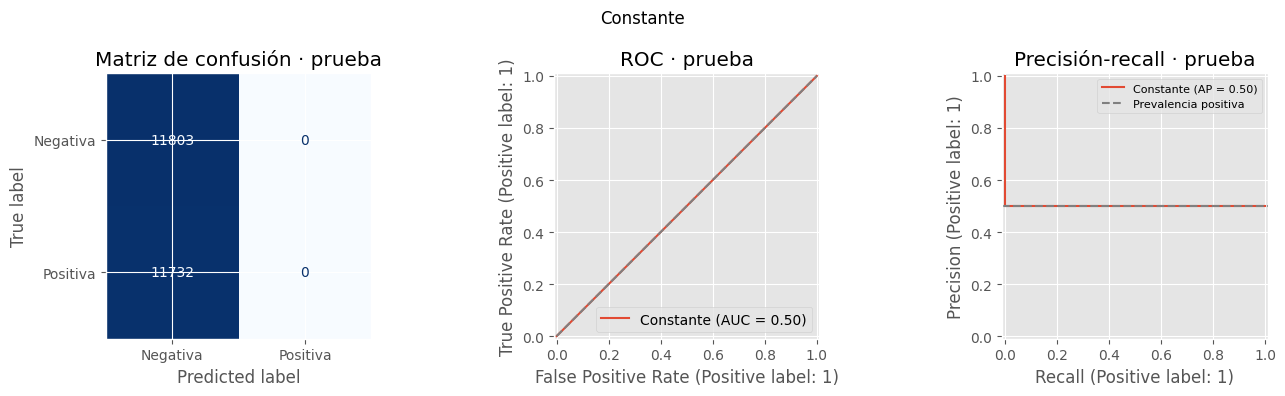

accuracy  precision_pos  recall_pos  F1_pos  F1_neg  \
modelo    particion                                                        
Constante train        0.5007            0.0         0.0     0.0  0.6673   
          test         0.5015            0.0         0.0     0.0  0.6680   

                     F1_macro  ROC_AUC  AP_pos  
modelo    particion                             
Constante train        0.3336      0.5  0.4993  
          test         0.3340      0.5  0.4985

,accuracy,precision_pos,recall_pos,F1_pos,F1_neg,F1_macro,ROC_AUC,AP_pos,tiempo_ajuste_s,cumple_F1_pos,cumple_F1_neg
modelo,,,,,,,,,,,
Regresión logística,0.9048,0.9038,0.9054,0.9046,0.9050,0.9048,0.9658,0.9637,1.1811,True,True
SVM lineal,0.9033,0.9047,0.9010,0.9028,0.9038,0.9033,0.9661,0.9640,0.4812,True,True
Complement NB,0.8727,0.8913,0.8481,0.8691,0.8761,0.8726,0.9457,0.9420,0.0219,True,True
Constante,0.5015,0.0000,0.0000,0.0000,0.6680,0.3340,0.5000,0.4985,0.0010,False,False


In [14]:
evaluation_rows = []
for name, model in models.items():
    evaluation_rows.extend(evaluate_model(name, model, X_train, y_train, X_test, y_test))

results = pd.DataFrame(evaluation_rows)
test_results = results.loc[results['particion'].eq('test')].set_index('modelo').copy()
test_results['tiempo_ajuste_s'] = pd.Series(fit_times)
test_results['cumple_F1_pos'] = test_results['F1_pos'].ge(F1_TARGET)
test_results['cumple_F1_neg'] = test_results['F1_neg'].ge(F1_TARGET)
display(test_results.drop(columns='particion').round(4))
print('Modelo previamente seleccionado:', best_name)
print('F1 positivo en prueba:', round(test_results.loc[best_name, 'F1_pos'], 4))
print('F1 negativo en prueba:', round(test_results.loc[best_name, 'F1_neg'], 4))

              precision    recall  f1-score   support

    Negativa     0.9020    0.9056    0.9038     11803
    Positiva     0.9047    0.9010    0.9028     11732

    accuracy                         0.9033     23535
   macro avg     0.9033    0.9033    0.9033     23535
weighted avg     0.9033    0.9033    0.9033     23535



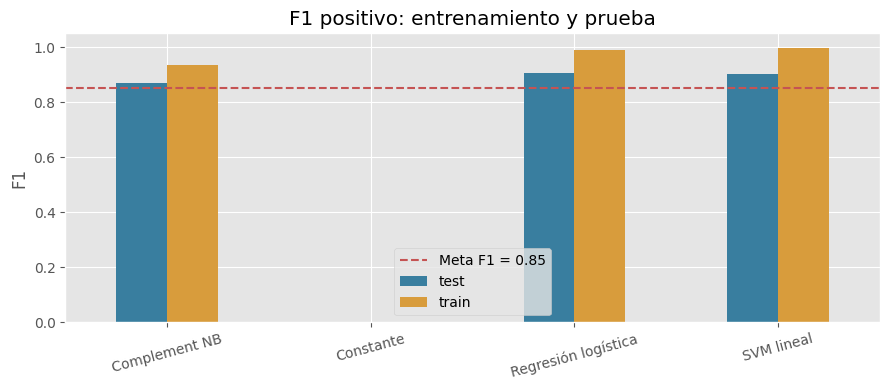

particion,test,train,brecha
modelo,,,
Complement NB,0.8691,0.9363,0.0671
Constante,0.0000,0.0000,0.0000
Regresión logística,0.9046,0.9890,0.0844
SVM lineal,0.9028,0.9956,0.0928


In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
comparison = results.pivot(index='modelo', columns='particion', values='F1_pos')
comparison.plot.bar(ax=ax, rot=15, color=['#397e9f', '#d89c3c'])
ax.axhline(F1_TARGET, linestyle='--', color='#c55353', label='Meta F1 = 0.85')
ax.set(title='F1 positivo: entrenamiento y prueba', ylabel='F1', xlabel='', ylim=(0, 1.05))
ax.legend()
plt.tight_layout()
plt.show()

gaps = comparison.assign(brecha=comparison['train'] - comparison['test'])
display(gaps.round(4))
print(classification_report(y_test, models[best_name].predict(X_test),
                            target_names=['Negativa', 'Positiva'], digits=4, zero_division=0))

<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Excelente! Entrenaste diferentes modelos y se obtuvieron métricas bastante buenas! Siempre procura buscar una forma amigable de explicar el resultado del performance en tu modelo, por ejemplo, utilizar gráficas para explicar el comportamiento de los modelos
</div>

### 7.5. Inspección de errores del modelo seleccionado

In [16]:
test_predictions = models[best_name].predict(X_test)
test_scores = positive_score(models[best_name], X_test)
errors = df_reviews_test[['review', 'pos']].copy()
errors['prediccion'] = test_predictions
errors['score_positivo'] = test_scores
errors = errors.loc[errors['pos'].ne(errors['prediccion'])]
print('Errores:', len(errors), 'de', len(y_test))
if len(errors):
    error_sample = errors.sample(n=min(6, len(errors)), random_state=RANDOM_STATE).copy()
    error_sample['review'] = error_sample['review'].str.slice(0, 500)
    with pd.option_context('display.max_colwidth', 500):
        display(error_sample)

Errores: 2275 de 23535


,review,pos,prediccion,score_positivo
43589,"Black comedy isn't always an easy sell. Every now and then you get a black comedy that is hugely successful, like Fargo, for example. But usually they don't often find big audiences. People seem to either set their minds for comedy, or for serious mayhem. There doesn't seem to be a big market for a good mixture of both. Throw Momma From the Train was a fairly decent hit, yet few people seem to remember much about it in this day and age. Danny DeVito just about hit this one all the way out of...",1,0,-0.091446
26783,"I LOVED this program, and for years searched for it on video. I've contacted a great many folks in my attempts to get a copy...to no avail. I DO, however, have the second half of the program. I would be willing to share MY half, with anyone who can give me a copy of the FIRST half of this show. I'd offer to provide copies of what I have to anyone, BUT it's just only part of the program...so it's just not an adequate representation of the show. There are a few folks selling this on EBAY for s...",1,0,-0.046894
17845,"The NYT review says that Sigourney Weaver's character is taut and frustrated, and, later, that she could be the sister of MTM's character in Ordinary People. Say, WHAT? No way. This lady was quirky from the start. NOTHING like MTM in Ordinary People. Sorry. Next, the NYT goes on to say that Sigourney Weaver's Sandy Travis and Jeff Daniel's Ben Travis are 40-something year olds, ""children of the 60s."" Ms Weaver must be dancing a jig. I believe at the time she made Imaginary Heroes she was in ...",1,0,-0.073291
7950,"I expected so much more than what I received from watching this movie. It is not that I object to literary license, (if that is what it should be called) especially when there is no overt attempt to say ""based on a true story."" But this movie is about Beethoven -- a real historical person who is so widely known and so deeply embedded into our musical experiences and I expected the movie to be true to history at least in the primary elements. This movie took such great exception from the hist...",0,1,0.068908
12704,"this is an adaptation of a Dirk Wittenborn book, which I did not read. young Finn Earl lives with his Mom Liz (Diane Lane) in a cramped lower East Side New York Apartment. he dreams of joining his Anthropologist father studying a fierce tribe in South America. Liz has boyfriends and does coke. when he is caught scoring coke for her, one of her customers (Liz is a legitimate masseuse) a rich Mr. Osborne bails her out in return for being his full time personal masseuse in his huge estate in Ne...",1,0,-0.147119
27221,"I loved the first 15 minutes, and I loved some of the dialogue in the tribunal--which proved to be the best showcase for the director's ahead-of-its-time method acting technique--but this movie ultimately disappoints. Even when viewed purely as a metaphor of the oppressor/oppressed dynamics that were and are prevalent in the relationship between the US government and its more ""disobedient"" citizens, it still lacks punch and believability, and ultimately left me looking at my watch hoping the...",0,1,0.391218


Los errores permiten inspeccionar opiniones mixtas, narración de la trama y frases cuyo sentido depende del contexto. Una reseña puede hablar de personajes o acontecimientos negativos y aun así valorar positivamente la película. TF-IDF representa términos y pares de términos, pero no comprende toda la estructura de un párrafo. Los ejemplos anteriores son una muestra de errores, no una clasificación exhaustiva de sus causas; un fragmento truncado puede omitir el juicio final.

## 8. Reseñas propias: clasificación con todos los modelos

Se escriben reseñas originales y se asigna una etiqueta esperada de forma manual, **antes de predecir**. Se incluyen opiniones claras, negaciones, opiniones mixtas y sarcasmo. Estas etiquetas representan la intención del autor y no un nuevo conjunto de prueba validado. Se utiliza exactamente la misma normalización y el vectorizador ya ajustado; no se vuelve a entrenar con ellas.

In [17]:
my_reviews = pd.DataFrame([
    ('The performances are wonderful and the story is deeply moving. I loved every minute.', 1, 'Positiva clara'),
    ('A beautiful film with memorable characters and an excellent ending. Highly recommended.', 1, 'Positiva clara'),
    ('The dialogue is sharp, the acting is convincing, and I would happily watch it again.', 1, 'Positiva clara'),
    ('The acting is terrible and the plot is painfully boring. A complete waste of time.', 0, 'Negativa clara'),
    ('I hated this movie. Nothing makes sense and the ending is awful.', 0, 'Negativa clara'),
    ('The characters are flat and the dialogue is dreadful. I regret watching it.', 0, 'Negativa clara'),
    ('I did not enjoy this movie. The attractive images cannot rescue its empty story.', 0, 'Negación'),
    ('This is not a bad movie. It is surprisingly touching and worth watching.', 1, 'Negación'),
    ('The first half is dull, but the brilliant ending makes the whole film worthwhile.', 1, 'Opinión mixta'),
    ('The actors are excellent, but the story is so tedious that I cannot recommend it.', 0, 'Opinión mixta'),
    ('What a masterpiece: two hours of people staring at walls. I want my evening back.', 0, 'Sarcasmo'),
    ('I expected a disaster, but I was wrong. This turned out to be a delightful film.', 1, 'Cambio de opinión'),
], columns=['review', 'esperada', 'tipo'])
my_reviews['review_norm'] = my_reviews['review'].map(normalize_text)
X_my = tfidf_vectorizer.transform(my_reviews['review_norm'])
my_predictions = pd.DataFrame(index=my_reviews.index)
my_scores = pd.DataFrame(index=my_reviews.index)
for name, model in models.items():
    my_predictions[name] = model.predict(X_my)
    score_label = f'{name} · ' + ('P(positiva)' if hasattr(model, 'predict_proba') else 'margen')
    my_scores[score_label] = positive_score(model, X_my)

with pd.option_context('display.max_colwidth', 160):
    display(pd.concat([my_reviews[['review', 'esperada', 'tipo']], my_predictions], axis=1))
display(my_scores.round(3))
print('0 = negativa; 1 = positiva. El margen SVM se clasifica como positivo si es mayor que 0.')

0 = negativa; 1 = positiva. El margen SVM se clasifica como positivo si es mayor que 0.


,review,esperada,tipo,Regresión logística,SVM lineal,Complement NB,Constante
0,The performances are wonderful and the story is deeply moving. I loved every minute.,1,Positiva clara,1,1,1,0
1,A beautiful film with memorable characters and an excellent ending. Highly recommended.,1,Positiva clara,1,1,1,0
2,"The dialogue is sharp, the acting is convincing, and I would happily watch it again.",1,Positiva clara,1,1,1,0
3,The acting is terrible and the plot is painfully boring. A complete waste of time.,0,Negativa clara,0,0,0,0
4,I hated this movie. Nothing makes sense and the ending is awful.,0,Negativa clara,0,0,0,0
5,The characters are flat and the dialogue is dreadful. I regret watching it.,0,Negativa clara,0,0,0,0
6,I did not enjoy this movie. The attractive images cannot rescue its empty story.,0,Negación,0,0,0,0
7,This is not a bad movie. It is surprisingly touching and worth watching.,1,Negación,1,1,1,0
8,"The first half is dull, but the brilliant ending makes the whole film worthwhile.",1,Opinión mixta,0,0,0,0
9,"The actors are excellent, but the story is so tedious that I cannot recommend it.",0,Opinión mixta,1,1,1,0


,Regresión logística · P(positiva),SVM lineal · margen,Complement NB · P(positiva),Constante · P(positiva)
0,0.986,1.348,0.957,0.0
1,0.998,2.204,0.974,0.0
2,0.793,0.581,0.637,0.0
3,0.000,-2.664,0.005,0.0
4,0.067,-0.912,0.081,0.0
5,0.135,-0.692,0.084,0.0
6,0.296,-0.353,0.362,0.0
7,0.817,0.676,0.745,0.0
8,0.281,-0.343,0.314,0.0
9,0.767,0.364,0.561,0.0


In [18]:
custom_rows = []
for name in models:
    predictions = my_predictions[name].to_numpy()
    expected = my_reviews['esperada'].to_numpy()
    custom_rows.append({
        'modelo': name,
        'aciertos_propias': int(np.sum(predictions == expected)),
        'n_propias': len(expected),
        'accuracy_propias': accuracy_score(expected, predictions),
        'F1_propias': f1_score(expected, predictions, zero_division=0),
        'F1_test': test_results.loc[name, 'F1_pos'],
    })
custom_results = pd.DataFrame(custom_rows).set_index('modelo')
display(custom_results.round(4))

# El modelo constante se excluye aquí para estudiar desacuerdos entre algoritmos de texto.
text_model_names = [name for name in models if name != 'Constante']
disagreement = my_predictions[text_model_names].nunique(axis=1).gt(1)
mistake = my_predictions[text_model_names].ne(my_reviews['esperada'], axis=0).any(axis=1)
print('Reseñas con desacuerdo entre algoritmos:', int(disagreement.sum()))
print('Reseñas con algún error entre algoritmos:', int(mistake.sum()))
with pd.option_context('display.max_colwidth', 170):
    display(pd.concat([my_reviews[['review', 'esperada', 'tipo']], my_predictions], axis=1)
            .loc[disagreement | mistake])

Reseñas con desacuerdo entre algoritmos: 1
Reseñas con algún error entre algoritmos: 4


,aciertos_propias,n_propias,accuracy_propias,F1_propias,F1_test
modelo,,,,,
Regresión logística,8,12,0.6667,0.6667,0.9046
SVM lineal,8,12,0.6667,0.6667,0.9028
Complement NB,9,12,0.7500,0.7273,0.8691
Constante,6,12,0.5000,0.0000,0.0000


,review,esperada,tipo,Regresión logística,SVM lineal,Complement NB,Constante
8,"The first half is dull, but the brilliant ending makes the whole film worthwhile.",1,Opinión mixta,0,0,0,0
9,"The actors are excellent, but the story is so tedious that I cannot recommend it.",0,Opinión mixta,1,1,1,0
10,What a masterpiece: two hours of people staring at walls. I want my evening back.,0,Sarcasmo,1,1,0,0
11,"I expected a disaster, but I was wrong. This turned out to be a delightful film.",1,Cambio de opinión,0,0,0,0


In [19]:
feature_names = tfidf_vectorizer.get_feature_names_out()
lexical_model = models['Regresión logística']
coef = lexical_model.coef_[0]
display(pd.DataFrame({
    'términos asociados a negativo': feature_names[np.argsort(coef)[:15]],
    'términos asociados a positivo': feature_names[np.argsort(coef)[-15:][::-1]],
}))
tokenizer = tfidf_vectorizer.build_analyzer()
vocabulary = tfidf_vectorizer.vocabulary_
def vocabulary_coverage(text):
    terms = tokenizer(text)
    return np.mean([term in vocabulary for term in terms]) if terms else 0.0

coverage = my_reviews[['tipo']].copy()
coverage['palabras'] = my_reviews['review_norm'].str.split().str.len()
coverage['fraccion_terminos_en_vocabulario'] = my_reviews['review_norm'].map(vocabulary_coverage)
display(coverage.round(3))

,términos asociados a negativo,términos asociados a positivo
0,bad,great
1,worst,excellent
2,awful,perfect
3,the worst,wonderful
4,boring,amazing
5,poor,the best
6,waste,best
7,terrible,today
8,no,fun
9,worse,loved


,tipo,palabras,fraccion_terminos_en_vocabulario
0,Positiva clara,14,0.880
1,Positiva clara,12,0.905
2,Positiva clara,15,0.815
3,Negativa clara,15,0.889
4,Negativa clara,12,0.952
5,Negativa clara,13,0.826
6,Negación,14,0.720
7,Negación,13,0.957
8,Opinión mixta,14,0.815
9,Opinión mixta,15,0.852


**Interpretación de las diferencias.** La prueba contiene miles de reseñas de IMDB, mientras que estas 12 reseñas son cortas, redactadas manualmente y enriquecidas con casos difíciles. Un solo error modifica mucho sus métricas: no corresponde concluir que un modelo generaliza mejor por acertar uno o dos ejemplos más. Las reseñas ambiguas también pueden admitir interpretaciones humanas diferentes.

En una opinión mixta, palabras como `excellent` pueden competir con `tedious`; el peso relativo cambia entre modelos. La regresión logística y SVM aprenden pesos discriminativos, mientras que Naive Bayes combina evidencia bajo supuestos simplificados. El sarcasmo puede usar elogios literales para expresar rechazo. Los bigramas capturan algunas negaciones, pero no razonamientos o giros que abarcan varias oraciones. Los términos fuera del vocabulario no aportan características: la tabla de cobertura ayuda a detectar ese límite, sin demostrar por sí sola la causa de un error.

Las probabilidades de Naive Bayes pueden ser extremas por su hipótesis de independencia; no se han calibrado. Los márgenes de SVM tienen otra escala y no se comparan numéricamente con probabilidades. El modelo constante asigna la misma clase a todas las reseñas, por lo que sus aciertos no evidencian comprensión del texto. Un resultado en español tampoco sería comparable: este modelo se entrenó con inglés.

## 9. Hallazgos y conclusiones

In [20]:
chosen = test_results.loc[best_name]
chosen_validation = selected_rows.loc[best_name, 'F1_pos']
chosen_train = comparison.loc[best_name, 'train']
chosen_custom = custom_results.loc[best_name]
passed = chosen['F1_pos'] >= F1_TARGET
negative_passed = chosen['F1_neg'] >= F1_TARGET
conclusion = f"""
1. **Datos:** {len(df_reviews):,} reseñas originales, {negative_pct:.2f}% negativas.
   Se preservaron las {len(df_reviews_test):,} reseñas de prueba y se entrenó con
   {len(df_reviews_train):,} textos después de limpiar repeticiones y coincidencias.
2. **Selección:** se eligió **{best_name}** mediante validación interna por película,
   con F1 positivo **{chosen_validation:.4f}**. Las decisiones no se basaron en las
   métricas de prueba. Se compararon tres algoritmos de texto y una referencia constante.
3. **Evaluación final del modelo elegido:** F1 positivo **{chosen['F1_pos']:.4f}**,
   F1 negativo **{chosen['F1_neg']:.4f}**, F1 macro **{chosen['F1_macro']:.4f}**,
   accuracy **{chosen['accuracy']:.4f}** y ROC-AUC **{chosen['ROC_AUC']:.4f}**.
   La meta de F1 positivo ≥ 0.85 **{'se cumple' if passed else 'no se cumple'}**;
   la misma meta para la clase negativa **{'también se cumple' if negative_passed else 'no se cumple'}**.
4. **Generalización:** F1 positivo de entrenamiento **{chosen_train:.4f}** frente
   a **{chosen['F1_pos']:.4f}** en prueba; brecha **{chosen_train-chosen['F1_pos']:.4f}**.
   La comparación permite detectar ajuste específico a entrenamiento; no garantiza
   rendimiento en otra población o idioma.
5. **Reseñas propias:** el modelo elegido acertó
   **{int(chosen_custom['aciertos_propias'])}/{len(my_reviews)}**. Esta muestra sirve
   para inspeccionar negaciones, opiniones mixtas y sarcasmo; no sustituye la prueba oficial.
6. **Recomendación:** usar el modelo elegido junto con su normalización y vectorizador.
   Antes de aplicarlo a una comunidad real, validar reseñas recientes y acordar el costo
   de bloquear una reseña positiva frente al de dejar pasar una negativa. Un cambio de
   umbral se debería decidir en una validación independiente, nunca optimizando la prueba.
7. **Límites:** clasificación binaria sin neutralidad, corpus inglés, pérdida de contexto
   de largo alcance y probabilidades sin calibrar. No se evaluó BERT ni se atribuye a
   estos métodos capacidad de comprensión semántica completa.
"""
display(Markdown(conclusion))
assert passed, 'El modelo elegido no alcanzó F1 positivo 0.85 en prueba.'
assert negative_passed, 'El F1 de la clase negativa no alcanzó 0.85.'


1. **Datos:** 47,331 reseñas originales, 50.10% negativas.
   Se preservaron las 23,535 reseñas de prueba y se entrenó con
   23,755 textos después de limpiar repeticiones y coincidencias.
2. **Selección:** se eligió **SVM lineal** mediante validación interna por película,
   con F1 positivo **0.8996**. Las decisiones no se basaron en las
   métricas de prueba. Se compararon tres algoritmos de texto y una referencia constante.
3. **Evaluación final del modelo elegido:** F1 positivo **0.9028**,
   F1 negativo **0.9038**, F1 macro **0.9033**,
   accuracy **0.9033** y ROC-AUC **0.9661**.
   La meta de F1 positivo ≥ 0.85 **se cumple**;
   la misma meta para la clase negativa **también se cumple**.
4. **Generalización:** F1 positivo de entrenamiento **0.9956** frente
   a **0.9028** en prueba; brecha **0.0928**.
   La comparación permite detectar ajuste específico a entrenamiento; no garantiza
   rendimiento en otra población o idioma.
5. **Reseñas propias:** el modelo elegido acertó
   **8/12**. Esta muestra sirve
   para inspeccionar negaciones, opiniones mixtas y sarcasmo; no sustituye la prueba oficial.
6. **Recomendación:** usar el modelo elegido junto con su normalización y vectorizador.
   Antes de aplicarlo a una comunidad real, validar reseñas recientes y acordar el costo
   de bloquear una reseña positiva frente al de dejar pasar una negativa. Un cambio de
   umbral se debería decidir en una validación independiente, nunca optimizando la prueba.
7. **Límites:** clasificación binaria sin neutralidad, corpus inglés, pérdida de contexto
   de largo alcance y probabilidades sin calibrar. No se evaluó BERT ni se atribuye a
   estos métodos capacidad de comprensión semántica completa.


<div class="alert alert-block alert-success">
<b>Comentario general (1ra Iteracion)</b> <a class=“tocSkip”></a>

Hiciste un buen trabajo entrenando los diferentes modelos, obtuviste buenos scores en las métricas de evaluación con los mismos.
    
Cómo pudiste observar a lo largo de este proyecto para que los modelos puedan entender nuestro lenguaje o cómo los humanos se comunican primero hay que transformar estos textos a números utilizando vectorización para poder tener una representación de estos y que los modelos puedan realizar las asociaciones necesarias y así obtener predicciones.

    
Saludos!
</div>

## Lista de comprobación

- [x] Datos cargados y revisados.
- [x] EDA y conclusión sobre el equilibrio de clases.
- [x] Normalización y auditoría de duplicados.
- [x] Partición oficial de prueba conservada.
- [x] TF-IDF ajustado sin aprender vocabulario de validación ni prueba.
- [x] Tres algoritmos distintos y un modelo constante.
- [x] Hiperparámetros elegidos con validación interna.
- [x] Evaluación final con F1 positivo, negativo, macro y métricas adicionales.
- [x] Comprobación ejecutable de F1 ≥ 0.85.
- [x] Reseñas propias clasificadas con todos los modelos y análisis de diferencias.
- [x] Hallazgos, recomendación y limitaciones.

La aceptación final corresponde al revisor del proyecto.